# 04 — Pré-treinamento do LSTM (Bristol + derivas sintéticas)

Pré-treinamento do ramo ambiental (seções 3.3.2 e 7.3):

* **Entrada:** janela de 30 passos de 10 s (5 min) com temperatura, umidade e desvio de pressão, normalizados em [0, 1] (notebook 02).
* **Arquitetura:** LSTM com 32 unidades, densa de 16 unidades e saída de **quatro classes** (Normal, Atenção, Crítico, Falha).
* **Treino:** entropia cruzada ponderada pelo inverso da frequência das classes, Adam 10⁻³, lotes de 32, até 100 épocas, parada antecipada após 10 épocas; **cinco sementes**.
* **Avaliação no teste separada em janelas reais e sintéticas.** O teste (julho de 2022) contém calor real; as janelas reais são a evidência mais forte.
* **Implantação:** o LSTM é exportado como **um único passo** (x_t, h, c → h', c', probabilidades), executado 30 vezes por janela no firmware. A forma desenrolada completa ocuparia cerca de 150 KB; o passo único ocupa cerca de 17 KB em int8. O notebook verifica numericamente que as duas formas produzem o mesmo resultado.

**Ambiente:** GPU T4. O treino leva de 1 a 2 horas (cerca de 10 mil lotes por época).

> Nota: no Bristol, o rótulo é a regra térmica aplicada ao último passo; nesta etapa o LSTM aprende essencialmente essa regra. O ganho esperado do LSTM (tendência, umidade, ruído do sensor, rótulos do termo-higrômetro de referência) aparece no fine-tuning in situ.

In [1]:
# 1. Ambiente, versões e dados
import sys, os, json, numpy as np, pandas as pd, tensorflow as tf
print("Python", sys.version.split()[0], "| TensorFlow", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))
from google.colab import drive
drive.mount("/content/drive")

DADOS = "/content/drive/MyDrive/dissertacao_tinyml/bristol_preparado"
SAIDA = "/content/drive/MyDrive/dissertacao_tinyml/modelos/lstm"
os.makedirs(SAIDA, exist_ok=True)
NOMES = ["Normal", "Atenção", "Crítico", "Falha"]

def carregar(p):
    d = np.load(f"{DADOS}/{p}.npz")
    return d["X"].astype(np.float32), d["y"].astype(np.int32), d["sintetica"].astype(bool)
Xtr, ytr, str_ = carregar("treino"); Xva, yva, sva = carregar("validacao"); Xte, yte, ste = carregar("teste")
for n, y, s in [("treino", ytr, str_), ("validação", yva, sva), ("teste", yte, ste)]:
    print(f"{n:10s} n={len(y):7d}  classes={np.bincount(y, minlength=4)}  sintéticas={int(s.sum())}")

Python 3.13.15 | TensorFlow 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
treino     n= 330235  classes=[258877  24030  23695  23633]  sintéticas=94352
validação  n=  52703  classes=[41338  3827  3773  3765]  sintéticas=15056
teste      n=  66577  classes=[48679  8273  4818  4807]  sintéticas=19020


In [2]:
# 2. Modelo (e exportação de passo único para o firmware)
# ===== LSTM: treino com janela de 30 passos e exportação de UM passo para o firmware =====
import numpy as np, tensorflow as tf

UNIDADES, DENSA, N_CLASSES = 32, 16, 4

def criar_lstm(n_passos=30, n_atrib=3, unidades=UNIDADES, densa=DENSA):
    ent = tf.keras.Input(shape=(n_passos, n_atrib), name="janela")
    x = tf.keras.layers.LSTM(unidades, name="lstm")(ent)
    x = tf.keras.layers.Dense(densa, activation="relu", name="densa")(x)
    sai = tf.keras.layers.Dense(N_CLASSES, activation="softmax", name="saida")(x)
    return tf.keras.Model(ent, sai, name="lstm_amb")

def modelo_passo(modelo):
    """Um passo do LSTM + cabeça densa, com os MESMOS pesos do modelo treinado.
    Entradas: x_t (1,3), h (1,U), c (1,U). Saídas: h', c', probabilidades (1,4).
    Ordem das portas no Keras: i, f, g (candidato), o."""
    Wk, Wr, b = modelo.get_layer("lstm").get_weights()
    U = Wr.shape[0]
    x = tf.keras.Input((Wk.shape[0],), batch_size=1, name="x_t")
    h = tf.keras.Input((U,), batch_size=1, name="h")
    c = tf.keras.Input((U,), batch_size=1, name="c")
    zx = tf.keras.layers.Dense(4 * U, name="Wx")(x)
    zh = tf.keras.layers.Dense(4 * U, use_bias=False, name="Wh")(h)
    z = tf.keras.layers.Add()([zx, zh])
    i = tf.keras.layers.Activation("sigmoid")(z[:, 0:U])
    f = tf.keras.layers.Activation("sigmoid")(z[:, U:2 * U])
    g = tf.keras.layers.Activation("tanh")(z[:, 2 * U:3 * U])
    o = tf.keras.layers.Activation("sigmoid")(z[:, 3 * U:4 * U])
    c2 = tf.keras.layers.Add(name="c_novo")([tf.keras.layers.Multiply()([f, c]), tf.keras.layers.Multiply()([i, g])])
    h2 = tf.keras.layers.Multiply(name="h_novo")([o, tf.keras.layers.Activation("tanh")(c2)])
    d = tf.keras.layers.Dense(modelo.get_layer("densa").units, activation="relu", name="densa")(h2)
    p = tf.keras.layers.Dense(N_CLASSES, activation="softmax", name="saida")(d)
    m = tf.keras.Model([x, h, c], [h2, c2, p], name="lstm_passo")
    m.get_layer("Wx").set_weights([Wk, b]); m.get_layer("Wh").set_weights([Wr])
    m.get_layer("densa").set_weights(modelo.get_layer("densa").get_weights())
    m.get_layer("saida").set_weights(modelo.get_layer("saida").get_weights())
    return m

def rodar_passos_keras(mp, X):
    """Executa o modelo de passo 30 vezes por janela (referência em float)."""
    U = mp.input[1].shape[-1]
    out = np.zeros((len(X), N_CLASSES), np.float32)
    for n in range(len(X)):
        h = np.zeros((1, U), np.float32); c = np.zeros((1, U), np.float32)
        for t in range(X.shape[1]):
            h, c, p = [np.asarray(v) for v in mp([X[n, t:t+1], h, c], training=False)]
        out[n] = np.asarray(p)[0]
    return out

def coletar_estados(mp, X):
    """Triplas (x_t, h, c) visitadas pelo modelo em float — dados de calibração da quantização."""
    U = mp.input[1].shape[-1]; tri = []
    for n in range(len(X)):
        h = np.zeros((1, U), np.float32); c = np.zeros((1, U), np.float32)
        for t in range(X.shape[1]):
            tri.append((X[n, t:t+1].astype(np.float32), np.asarray(h, np.float32), np.asarray(c, np.float32)))
            h, c, _ = [np.asarray(v) for v in mp([X[n, t:t+1], h, c], training=False)]
    return tri

def converter_passo(mp, triplas=None):
    conv = tf.lite.TFLiteConverter.from_keras_model(mp)
    if triplas is not None:
        conv.optimizations = [tf.lite.Optimize.DEFAULT]
        conv.representative_dataset = lambda: ({"x_t": t[0], "h": t[1], "c": t[2]} for t in triplas)
        conv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
        conv.inference_input_type = tf.int8; conv.inference_output_type = tf.int8
    return conv.convert()


def rodar_passos_tflite(modelo_bytes, X, Interpreter):
    """Executa o modelo de passo (TFLite, float32 ou int8) 30 vezes por janela, como o firmware fará:
    estado zerado no início da janela; h e c realimentados a cada passo (re-quantizados se int8)."""
    it = Interpreter(model_content=modelo_bytes); it.allocate_tensors()
    ent = {("x" if "x_t" in d["name"] else "h" if d["name"].endswith("_h:0") else "c"): d for d in it.get_input_details()}
    sai = sorted(it.get_output_details(), key=lambda d: int(d["name"].split(":")[-1]))   # ordem: h', c', prob
    oh, oc, op = sai
    assert op["shape"][-1] == N_CLASSES
    def q(v, d):
        if d["dtype"] != np.int8: return v.astype(np.float32)
        s, z = d["quantization"]; return np.clip(np.round(v / s + z), -128, 127).astype(np.int8)
    def dq(v, d):
        if d["dtype"] != np.int8: return v.astype(np.float32)
        s, z = d["quantization"]; return (v.astype(np.float32) - z) * s
    U = ent["h"]["shape"][-1]; res = np.zeros((len(X), N_CLASSES), np.float32)
    for n in range(len(X)):
        h = np.zeros((1, U), np.float32); c = np.zeros((1, U), np.float32)
        for t in range(X.shape[1]):
            it.set_tensor(ent["x"]["index"], q(X[n, t:t+1], ent["x"]))
            it.set_tensor(ent["h"]["index"], q(h, ent["h"])); it.set_tensor(ent["c"]["index"], q(c, ent["c"]))
            it.invoke()
            h = dq(it.get_tensor(oh["index"]), oh); c = dq(it.get_tensor(oc["index"]), oc)
        res[n] = dq(it.get_tensor(op["index"]), op)[0]
    return res, {"x": ent["x"]["quantization"], "h_ent": ent["h"]["quantization"], "c_ent": ent["c"]["quantization"],
                 "h_sai": oh["quantization"], "c_sai": oc["quantization"], "prob": op["quantization"]}

HP = {"lr": 1e-3, "lote": 32, "epocas": 100, "paciencia": 10}
SEMENTES = [0, 1, 2, 3, 4]
cont = np.bincount(ytr, minlength=4); PESOS = {c: len(ytr) / (4 * n) for c, n in enumerate(cont)}
print("Pesos das classes:", {NOMES[k]: round(v, 3) for k, v in PESOS.items()})
criar_lstm(Xtr.shape[1], Xtr.shape[2]).summary()

Pesos das classes: {'Normal': np.float64(0.319), 'Atenção': np.float64(3.436), 'Crítico': np.float64(3.484), 'Falha': np.float64(3.493)}


Model: "lstm_amb"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ janela (InputLayer)             │ (None, 30, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 4)              │            68 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,204 (20.33 KB)

 Trainable params: 5,204 (20.33 KB)

 Non-trainable params: 0 (0.00 B)

In [3]:
# 3. Treino com cinco sementes; teste separado em janelas reais e sintéticas
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, f1_score, confusion_matrix

def metricas(y, prob):
    pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, labels=[0, 1, 2, 3], zero_division=0)
    m = {"acuracia": accuracy_score(y, pred), "f1_macro": f1_score(y, pred, labels=[0, 1, 2, 3], average="macro", zero_division=0)}
    for k, nome in enumerate(NOMES):
        m[f"precisao_{nome}"], m[f"recall_{nome}"], m[f"f1_{nome}"] = p[k], r[k], f[k]
    return m

resultados, historicos = [], {}
for s in SEMENTES:
    tf.keras.utils.set_random_seed(s)
    modelo = criar_lstm(Xtr.shape[1], Xtr.shape[2])
    modelo.compile(optimizer=tf.keras.optimizers.Adam(HP["lr"]), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    parada = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=HP["paciencia"], restore_best_weights=True)
    h = modelo.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=HP["epocas"], batch_size=HP["lote"],
                   class_weight=PESOS, callbacks=[parada], verbose=2)
    historicos[s] = h.history
    pva = modelo.predict(Xva, batch_size=1024, verbose=0); pte = modelo.predict(Xte, batch_size=1024, verbose=0)
    m = {"semente": s, "epocas": len(h.history["loss"]),
         "f1_macro_validacao": f1_score(yva, pva.argmax(1), average="macro")}
    m.update({f"teste_{k}": v for k, v in metricas(yte, pte).items()})
    m.update({f"reais_{k}": v for k, v in metricas(yte[~ste], pte[~ste]).items()})
    m.update({f"sinteticas_{k}": v for k, v in metricas(yte[ste], pte[ste]).items()})
    resultados.append(m); modelo.save(f"{SAIDA}/lstm_semente{s}.keras")
    print(f"semente {s}: F1 macro teste = {m['teste_f1_macro']:.4f} | reais = {m['reais_f1_macro']:.4f} | "
          f"sintéticas = {m['sinteticas_f1_macro']:.4f} | recall Falha = {m['teste_recall_Falha']:.4f}")

res = pd.DataFrame(resultados).set_index("semente"); res.to_csv(f"{SAIDA}/resultados_sementes.csv")
resumo = res.agg(["mean", "std"]).T; resumo.to_csv(f"{SAIDA}/resultados_media_desvio.csv")
display(resumo.loc[[c for c in resumo.index if c.endswith(("acuracia", "f1_macro")) or "recall" in c]].round(4))

Epoch 1/100
10320/10320 - 71s - 7ms/step - accuracy: 0.9636 - loss: 0.1849 - val_accuracy: 0.9928 - val_loss: 0.0232
Epoch 2/100
10320/10320 - 65s - 6ms/step - accuracy: 0.9883 - loss: 0.0556 - val_accuracy: 0.9887 - val_loss: 0.0226
Epoch 3/100
10320/10320 - 66s - 6ms/step - accuracy: 0.9932 - loss: 0.0323 - val_accuracy: 0.9931 - val_loss: 0.0152
Epoch 4/100
10320/10320 - 66s - 6ms/step - accuracy: 0.9946 - loss: 0.0244 - val_accuracy: 0.9994 - val_loss: 0.0051
Epoch 5/100
10320/10320 - 64s - 6ms/step - accuracy: 0.9955 - loss: 0.0195 - val_accuracy: 0.9990 - val_loss: 0.0052
Epoch 6/100
10320/10320 - 66s - 6ms/step - accuracy: 0.9906 - loss: 0.0485 - val_accuracy: 0.9910 - val_loss: 0.0268
Epoch 7/100
10320/10320 - 64s - 6ms/step - accuracy: 0.9908 - loss: 0.0504 - val_accuracy: 0.9965 - val_loss: 0.0105
Epoch 8/100
10320/10320 - 64s - 6ms/step - accuracy: 0.9952 - loss: 0.0254 - val_accuracy: 0.9995 - val_loss: 0.0039
Epoch 9/100
10320/10320 - 64s - 6ms/step - accuracy: 0.9962 - lo

,mean,std
teste_acuracia,0.9948,0.0015
teste_f1_macro,0.9937,0.0018
teste_recall_Normal,0.9998,0.0002
teste_recall_Atenção,0.9594,0.0125
teste_recall_Crítico,0.9998,0.0004
teste_recall_Falha,0.9997,0.0004
reais_acuracia,0.9929,0.0022
reais_f1_macro,0.9779,0.0133
reais_recall_Normal,1.0000,0.0000
reais_recall_Atenção,0.9044,0.0293


Semente escolhida (maior F1 macro na validação): 2


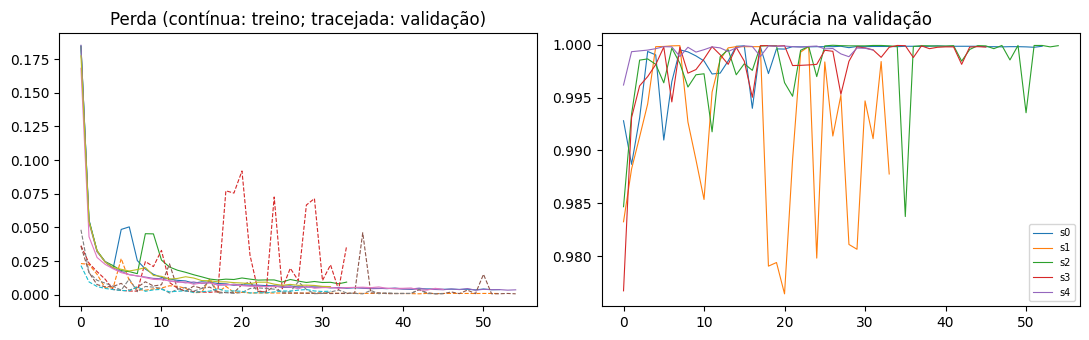


teste completo (linhas: real; colunas: predito ['Normal', 'Atenção', 'Crítico', 'Falha'])
[[48656    23     0     0]
 [  196  8077     0     0]
 [    0     1  4817     0]
 [    0     0     0  4807]]

teste — janelas REAIS (linhas: real; colunas: predito ['Normal', 'Atenção', 'Crítico', 'Falha'])
[[43924     0     0     0]
 [  196  3322     0     0]
 [    0     1    62     0]
 [    0     0     0    52]]

teste — janelas SINTÉTICAS (linhas: real; colunas: predito ['Normal', 'Atenção', 'Crítico', 'Falha'])
[[4732   23    0    0]
 [   0 4755    0    0]
 [   0    0 4755    0]
 [   0    0    0 4755]]


In [4]:
# 4. Modelo escolhido (pela validação), curvas e matrizes de confusão
import matplotlib.pyplot as plt
ESCOLHIDA = int(res["f1_macro_validacao"].idxmax())
print("Semente escolhida (maior F1 macro na validação):", ESCOLHIDA)
modelo = tf.keras.models.load_model(f"{SAIDA}/lstm_semente{ESCOLHIDA}.keras")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for s, h in historicos.items():
    ax[0].plot(h["loss"], lw=.8); ax[0].plot(h["val_loss"], "--", lw=.8)
    ax[1].plot(h["val_accuracy"], lw=.8, label=f"s{s}")
ax[0].set_title("Perda (contínua: treino; tracejada: validação)"); ax[1].set_title("Acurácia na validação")
ax[1].legend(fontsize=7); plt.tight_layout(); plt.savefig(f"{SAIDA}/curvas_treino.png", dpi=150); plt.show()

pte = modelo.predict(Xte, batch_size=1024, verbose=0)
for nome, sel in [("teste completo", slice(None)), ("teste — janelas REAIS", ~ste), ("teste — janelas SINTÉTICAS", ste)]:
    cm = confusion_matrix(yte[sel], pte[sel].argmax(1), labels=[0, 1, 2, 3])
    print(f"\n{nome} (linhas: real; colunas: predito {NOMES})"); print(cm)

In [5]:
# 5. Exportação: modelo de passo único (float32 e int8) e verificação de equivalência
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter

mp = modelo_passo(modelo)
amostra = np.random.default_rng(0).choice(len(Xte), 20, replace=False)
dif = np.abs(modelo.predict(Xte[amostra], verbose=0) - rodar_passos_keras(mp, Xte[amostra])).max()
print(f"Diferença máxima LSTM completo x passo único (Keras): {dif:.2e}")

# Calibração da quantização: estados visitados em 25 janelas de treino por classe
rng = np.random.default_rng(1)
cal = np.concatenate([rng.choice(np.where(ytr == c)[0], 25, replace=False) for c in range(4)])
triplas = coletar_estados(mp, Xtr[cal])
triplas = [triplas[i] for i in rng.choice(len(triplas), min(2000, len(triplas)), replace=False)]
tfl_f32 = converter_passo(mp); tfl_i8 = converter_passo(mp, triplas)
open(f"{SAIDA}/lstm_passo_float32.tflite", "wb").write(tfl_f32)
open(f"{SAIDA}/lstm_passo_int8.tflite", "wb").write(tfl_i8)
print(f"Passo único — float32: {len(tfl_f32)/1024:.1f} KB | int8: {len(tfl_i8)/1024:.1f} KB | "
      f"redução: {100*(1-len(tfl_i8)/len(tfl_f32)):.1f}%  | parâmetros: {modelo.count_params()}")

# Referência: tamanho da forma desenrolada completa (pode falhar em algumas versões)
try:
    ent = tf.keras.Input((Xtr.shape[1], Xtr.shape[2]))
    x = tf.keras.layers.LSTM(UNIDADES, unroll=True, name="lstm")(ent)
    x = tf.keras.layers.Dense(DENSA, activation="relu", name="densa")(x)
    des = tf.keras.Model(ent, tf.keras.layers.Dense(N_CLASSES, activation="softmax", name="saida")(x))
    des.set_weights(modelo.get_weights())
    cv = tf.lite.TFLiteConverter.from_keras_model(des); cv.optimizations = [tf.lite.Optimize.DEFAULT]
    cv.representative_dataset = lambda: ([Xtr[i:i+1]] for i in cal)
    cv.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    cv.inference_input_type = tf.int8; cv.inference_output_type = tf.int8
    print(f"Forma desenrolada completa (int8), só para comparação: {len(cv.convert())/1024:.1f} KB")
except Exception as e:
    print("Forma desenrolada não convertida:", type(e).__name__)

Diferença máxima LSTM completo x passo único (Keras): 1.03e-07
Saved artifact at '/tmp/tmpcqddoqlb'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(1, 3), dtype=tf.float32, name='x_t'), TensorSpec(shape=(1, 32), dtype=tf.float32, name='h'), TensorSpec(shape=(1, 32), dtype=tf.float32, name='c')]
Output Type:
  List[TensorSpec(shape=(1, 32), dtype=tf.float32, name=None), TensorSpec(shape=(1, 32), dtype=tf.float32, name=None), TensorSpec(shape=(1, 4), dtype=tf.float32, name=None)]
Captures:
  132494851389008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132494851378256: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132494851382672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132494851383248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132494851387472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132494851378832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132494851382864: Tenso

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Passo único — float32: 25.8 KB | int8: 16.9 KB | redução: 34.4%  | parâmetros: 5204
Saved artifact at '/tmp/tmpe31bf43w'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30, 3), dtype=tf.float32, name='keras_tensor_42')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  132497667389776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132497024300816: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132497024293328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132497024301200: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132497024288144: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132497024299472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132497024292560: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Forma desenrolada completa (int8), só para comparação: 149.1 KB


In [6]:
# 6. int8 x float32 no teste (amostra estratificada de 400 janelas por classe, reais e sintéticas)
rng = np.random.default_rng(2)
idx = np.concatenate([rng.choice(np.where(yte == c)[0], min(400, (yte == c).sum()), replace=False) for c in range(4)])
p32, _ = rodar_passos_tflite(tfl_f32, Xte[idx], Interpreter)
p8, qparams = rodar_passos_tflite(tfl_i8, Xte[idx], Interpreter)
comp = pd.DataFrame({"float32": metricas(yte[idx], p32), "int8": metricas(yte[idx], p8)})
comp["diferença"] = comp["int8"] - comp["float32"]
display(comp.round(4)); comp.to_csv(f"{SAIDA}/float32_vs_int8.csv")
print("Concordância de predições float32 x int8:", f"{100*(p32.argmax(1) == p8.argmax(1)).mean():.2f}%")
q = {k: [float(v[0]), int(v[1])] for k, v in qparams.items()}
json.dump({"semente": ESCOLHIDA, "unidades": UNIDADES, "n_passos": int(Xtr.shape[1]), "quantizacao": q,
           "ordem_saidas": ["h_novo", "c_novo", "probabilidades"],
           "uso": "zerar h e c no início de cada janela; executar 30 passos; ler probabilidades no último"},
          open(f"{SAIDA}/lstm_int8_quantizacao.json", "w"), indent=2, ensure_ascii=False)
print("Parâmetros de quantização (o firmware precisa deles):", q)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


,float32,int8,diferença
acuracia,0.9912,0.8550,-0.1362
f1_macro,0.9912,0.8494,-0.1419
precisao_Normal,0.9662,0.9242,-0.0420
recall_Normal,1.0000,0.9750,-0.0250
f1_Normal,0.9828,0.9489,-0.0339
precisao_Atenção,1.0000,0.7041,-0.2959
recall_Atenção,0.9650,0.9100,-0.0550
f1_Atenção,0.9822,0.7939,-0.1883
precisao_Crítico,1.0000,0.9200,-0.0800
recall_Crítico,1.0000,0.5750,-0.4250


Concordância de predições float32 x int8: 84.62%
Parâmetros de quantização (o firmware precisa deles): {'x': [0.00343911862000823, -128], 'h_ent': [0.005481901578605175, 22], 'c_ent': [0.17507393658161163, -6], 'h_sai': [0.005645405035465956, 18], 'c_sai': [0.1807021200656891, -6], 'prob': [0.00390625, -128]}


In [7]:
# 7. Vetor C para o firmware (xxd), com alinhamento de 16 bytes
os.chdir(SAIDA)
!which xxd > /dev/null || apt-get -qq install -y xxd > /dev/null
!xxd -i lstm_passo_int8.tflite > lstm_int8_model.h
h = open("lstm_int8_model.h").read().replace("unsigned char", "alignas(16) const unsigned char", 1)
h = h.replace("unsigned int", "const unsigned int", 1)
open("lstm_int8_model.h", "w").write("// Gerado por xxd -i a partir de lstm_passo_int8.tflite\n" + h)
print(open("lstm_int8_model.h").read()[:250], "...")

// Gerado por xxd -i a partir de lstm_passo_int8.tflite
alignas(16) const unsigned char lstm_passo_int8_tflite[] = {
  0x1c, 0x00, 0x00, 0x00, 0x54, 0x46, 0x4c, 0x33, 0x14, 0x00, 0x20, 0x00,
  0x1c, 0x00, 0x18, 0x00, 0x14, 0x00, 0x10, 0x00, 0x0c, 0x0 ...


## Resultado

Em `dissertacao_tinyml/modelos/lstm/`: resultados por semente e média ± desvio (teste completo, reais e sintéticas), curvas, os dois `.tflite` do passo único (Tabela 10), a comparação int8 × float32, os parâmetros de quantização e o `lstm_int8_model.h`.